In [1]:
import sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from src.data_prep import filter_residential, trim_price_outliers

sns.set_palette('colorblind')

# land registry uses single-letter codes -- map to readable labels for every chart/table below
PROPERTY_TYPE_LABELS = {'F': 'Flat/Maisonette', 'S': 'Semi-detached', 'T': 'Terraced', 'D': 'Detached', 'O': 'Other'}
OLD_NEW_LABELS = {'N': 'Existing property', 'Y': 'New build'}
DURATION_LABELS = {'F': 'Freehold', 'L': 'Leasehold'}
CATEGORY_LABELS = {'A': 'Standard sale', 'B': 'Other (repossession, right-to-buy, etc.)'}

df = pd.read_csv('../data/processed/london_house_prices.csv', parse_dates=['date_of_transfer'])
df.shape

def format_price_stats(desc):
    # describe() mixes a row count with £ stats -- round the £ fields to the
    # nearest pound (fractions of a penny on a six-figure price aren't meaningful),
    # keep count as a plain integer
    fmt = desc.astype(float).map('£{:,.0f}'.format)
    fmt['count'] = int(desc['count'])
    return fmt

## how to read this notebook

quick reference for terms used below:

- **log scale**: house prices are heavily skewed -- most sales cluster at the low end with a long tail of expensive ones. taking log10 of price compresses that tail so patterns are visible, and it's the scale the models are actually trained on (roughly: +0.3 on this scale means the price doubled).
- **H3 hexagon ("hex")**: the map is divided into equal-sized six-sided cells, like a honeycomb, so nearby sales can be grouped consistently -- postcodes and boroughs vary too much in size and shape for that.
- **freehold vs leasehold**: freehold means owning the property and the land outright. leasehold means owning the property for a fixed term while the land is owned separately -- standard for flats in the UK, and it tracks property type closely rather than being an independent driver of price.
- **distance-to-centre**: straight-line distance from Charing Cross (London's conventional "zero point"), in km.
- **SDLT**: Stamp Duty Land Tax, the UK's property purchase tax -- referenced below because a threshold change on 1 April 2025 shows up clearly in the data.

## missingness

saon/locality nulls are expected (not every address has a sub-unit or locality). price/date/postcode/coords are the fields that matter and have zero nulls.

In [2]:
df.isnull().mean().sort_values(ascending=False)

locality             0.936468
saon                 0.623066
street               0.000020
lat                  0.000000
record_status        0.000000
ppd_category_type    0.000000
county               0.000000
district             0.000000
town_city            0.000000
transaction_id       0.000000
price                0.000000
paon                 0.000000
duration             0.000000
old_new              0.000000
property_type        0.000000
postcode             0.000000
date_of_transfer     0.000000
long                 0.000000
dtype: float64

## category type / property type

the land registry tags every sale with a PPD category: **A** = standard/arm's-length sale, **B** = other (repossessions, buy-to-lets, transfers under power of sale, etc.). category B and property_type "Other" (commercial) both carry extreme non-residential prices, up to £793m -- this project is a residential AVM (automated valuation model), so both get filtered out via `filter_residential`.

In [3]:
df.assign(category=df['ppd_category_type'].map(CATEGORY_LABELS)).groupby('category')['price'].describe().apply(format_price_stats, axis=1)

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
"Other (repossession, right-to-buy, etc.)",61550,"£1,132,541","£6,077,833",£100,"£290,000","£427,260","£662,000","£793,020,000"
Standard sale,241179,"£719,222","£1,431,864",£1,"£395,000","£530,000","£763,220","£540,000,000"


In [4]:
df = filter_residential(df)
df.shape, format_price_stats(df['price'].describe())

((241179, 18),
 count          241179
 mean         £719,222
 std        £1,431,864
 min                £1
 25%          £395,000
 50%          £530,000
 75%          £763,220
 max      £540,000,000
 Name: price, dtype: object)

## price outliers within category a

category a still has £1 transfers (non-arm's-length, e.g. family gifts) and at least one clear data error (a £540m terraced house in E4). floor + top-0.1% trim via `trim_price_outliers`; the remaining upper tail (£10-75m, mostly SW1X/W2/W11 flats) is plausible prime-london stock, kept as is.

In [5]:
df = trim_price_outliers(df)
df.shape, format_price_stats(df['price'].describe())

((240932, 18),
 count         240932
 mean        £699,096
 std         £663,675
 min          £46,500
 25%         £395,000
 50%         £530,000
 75%         £760,025
 max      £11,100,000
 Name: price, dtype: object)

## price distribution

raw price is heavily right-skewed (typical for house prices) -- log scale (see glossary above) is closer to normal and is what the models will target.

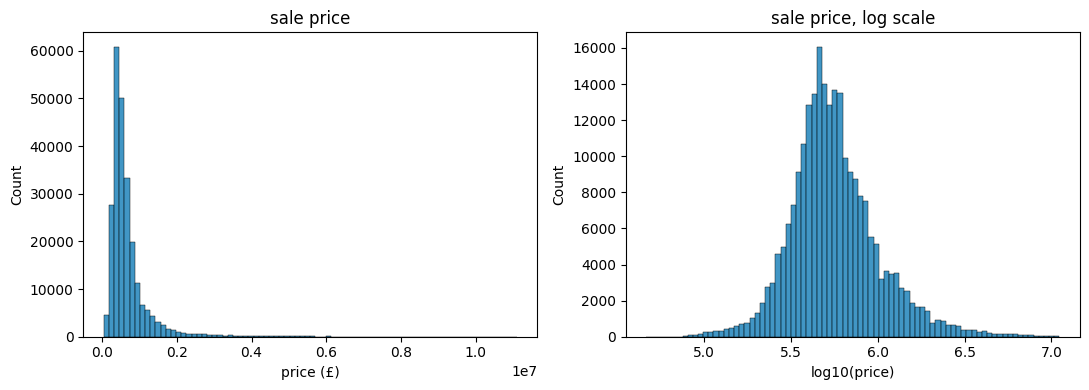

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price'], bins=80, ax=axes[0])
axes[0].set_title('sale price')
axes[0].set_xlabel('price (£)')
sns.histplot(df['price'].apply('log10'), bins=80, ax=axes[1])
axes[1].set_title('sale price, log scale')
axes[1].set_xlabel('log10(price)')
plt.tight_layout()

## price trend over time

monthly median, by property type.

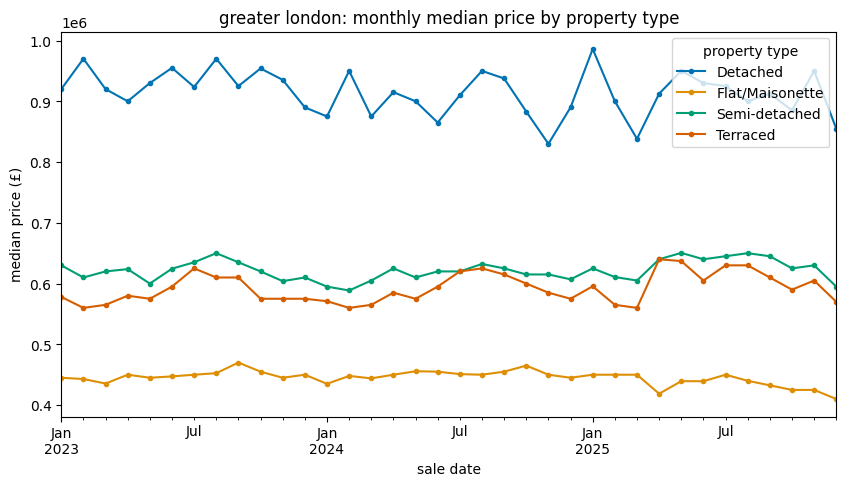

In [7]:
monthly = df.assign(property_type=df['property_type'].map(PROPERTY_TYPE_LABELS)).groupby(
    [df['date_of_transfer'].dt.to_period('M'), 'property_type']
)['price'].median().unstack()
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(10, 5), marker='o', markersize=3)
plt.ylabel('median price (£)')
plt.xlabel('sale date')
plt.title('greater london: monthly median price by property type')
plt.legend(title='property type')

## geographic scatter

sampled points (full set is too dense to render), colored by log price.

In [8]:
sample = df.sample(8000, random_state=0).copy()
sample['log_price'] = sample['price'].apply('log10')
fig = px.scatter_map(
    sample, lat='lat', lon='long', color='log_price',
    color_continuous_scale='viridis', map_style='carto-positron',
    zoom=8.5, height=650, opacity=0.6,
    labels={'log_price': 'price (log scale)'},
)
fig.update_layout(title='sampled sales across greater london, coloured by price')
fig.show()

## transaction volume over time

how many sales completed each month -- not just price, whether the market is actually active.

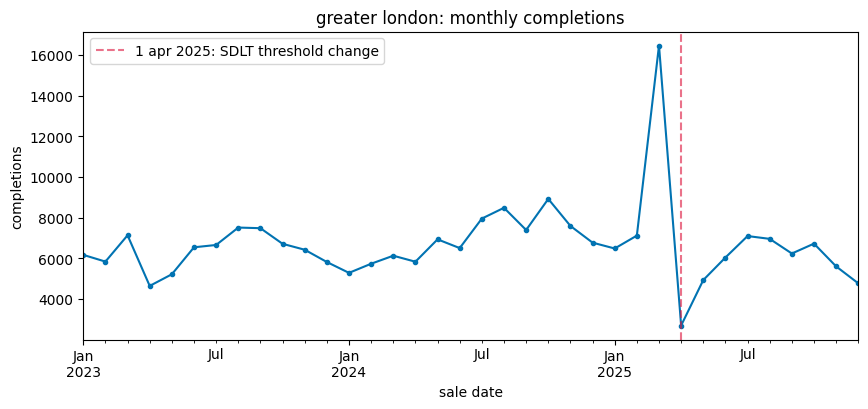

In [9]:
monthly_counts = df.groupby(df['date_of_transfer'].dt.to_period('M')).size()
monthly_counts.index = monthly_counts.index.to_timestamp()
monthly_counts.plot(figsize=(10, 4), marker='o', markersize=3)
plt.ylabel('completions')
plt.xlabel('sale date')
plt.title('greater london: monthly completions')
plt.axvline(pd.Timestamp('2025-04-01'), color='crimson', linestyle='--', alpha=0.6, label='1 apr 2025: SDLT threshold change')
plt.legend()

sharp spike in march 2025 (16.5k completions vs a 6-8k baseline) then a trough in april (2.7k) -- this lines up exactly with the SDLT nil-rate band reverting on 1 april 2025 (see glossary above), which pulled a wave of completions forward to beat the deadline. a real, dateable policy effect, not a data quality issue -- but it means march/april 2025 sit outside the normal seasonal pattern.

## property attributes

property type, new-build status, and tenure (freehold/leasehold) -- the categorical features going into every model.

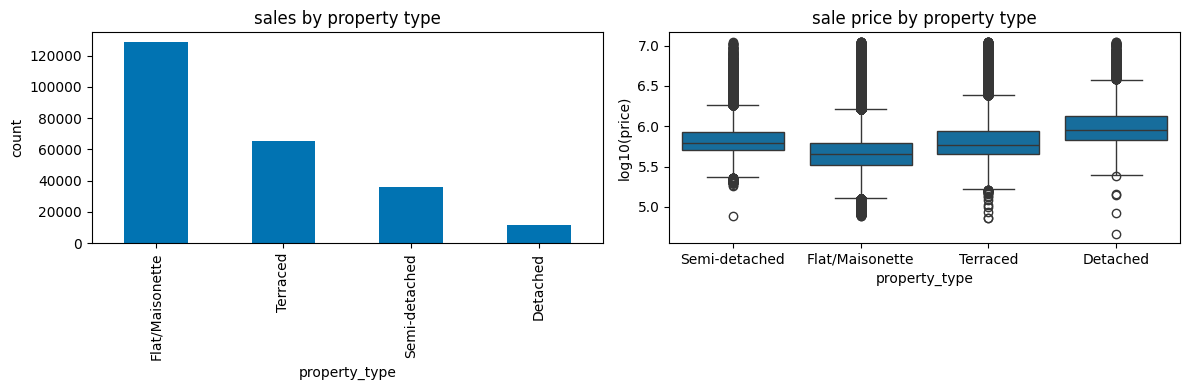

In [10]:
plot_df = df.assign(property_type=df['property_type'].map(PROPERTY_TYPE_LABELS))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_df['property_type'].value_counts().plot.bar(ax=axes[0])
axes[0].set_title('sales by property type')
axes[0].set_ylabel('count')
sns.boxplot(plot_df, x='property_type', y=plot_df['price'].apply('log10'), ax=axes[1])
axes[1].set_title('sale price by property type')
axes[1].set_ylabel('log10(price)')
plt.tight_layout()

flats/maisonettes and terraced houses dominate volume. detached houses carry the highest median price and widest spread; semi-detached sits between terraced and detached, as expected.

In [11]:
df.assign(old_new=df['old_new'].map(OLD_NEW_LABELS)).groupby('old_new')['price'].describe().apply(format_price_stats, axis=1)[['count', 'mean', '50%']].rename(columns={'50%': 'median'})

,count,mean,median
old_new,,,
Existing property,225668,"£691,003","£525,000"
New build,15264,"£818,747","£597,866"


new builds are a small share of sales (~6%) but carry a real premium over existing stock at the median.

In [12]:
pd.crosstab(
    df['property_type'].map(PROPERTY_TYPE_LABELS),
    df['duration'].map(DURATION_LABELS),
    normalize='index',
).round(3)

duration,Freehold,Leasehold
property_type,,
Detached,0.990,0.010
Flat/Maisonette,0.007,0.993
Semi-detached,0.978,0.022
Terraced,0.960,0.040


flats are almost entirely leasehold, houses are almost entirely freehold -- tenure and property type are highly collinear by construction (the UK's lease/freehold system, not price, drives this). worth keeping both as features regardless -- the modelling notebook's SHAP results show them splitting similar but not identical signal.

## seasonality

is there a month-of-year price effect on top of the year-over-year trend above, or is that chart just drift?

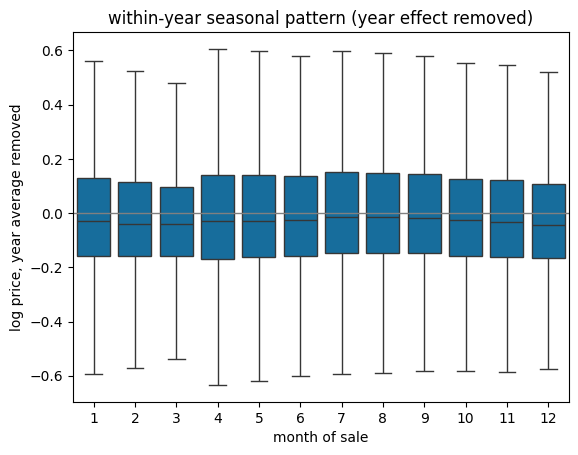

In [13]:
detrended = df.copy()
detrended['log_price'] = detrended['price'].apply('log10')
detrended['year_mean_log'] = detrended.groupby(detrended['date_of_transfer'].dt.year)['log_price'].transform('mean')
detrended['seasonal_resid'] = detrended['log_price'] - detrended['year_mean_log']
detrended['month'] = detrended['date_of_transfer'].dt.month

sns.boxplot(detrended, x='month', y='seasonal_resid', showfliers=False)
plt.ylabel('log price, year average removed')
plt.xlabel('month of sale')
plt.title('within-year seasonal pattern (year effect removed)')
plt.axhline(0, color='grey', linewidth=1)

mild but real seasonal pattern -- spring/summer months sit slightly above the year average, winter (esp. december/january) slightly below. small next to the property-attribute and location signal, but real enough that `sale_month` earns its place as a feature.

## hex resolution choice

`features.py` fixes the H3 hex size at resolution 8 (see glossary) -- checking that choice empirically here rather than taking a code comment on faith. resolution 7 hexes are roughly 5km across (too coarse), 8 are about 0.7 km² each, 9 are about 0.1 km² (much finer, thinner data per cell).

,n_hexes,min,median,90th percentile,max
7,375.0,1.0,520.0,1403.8,2816.0
8,2198.0,1.0,85.0,242.0,930.0
9,12220.0,1.0,14.0,42.0,443.0


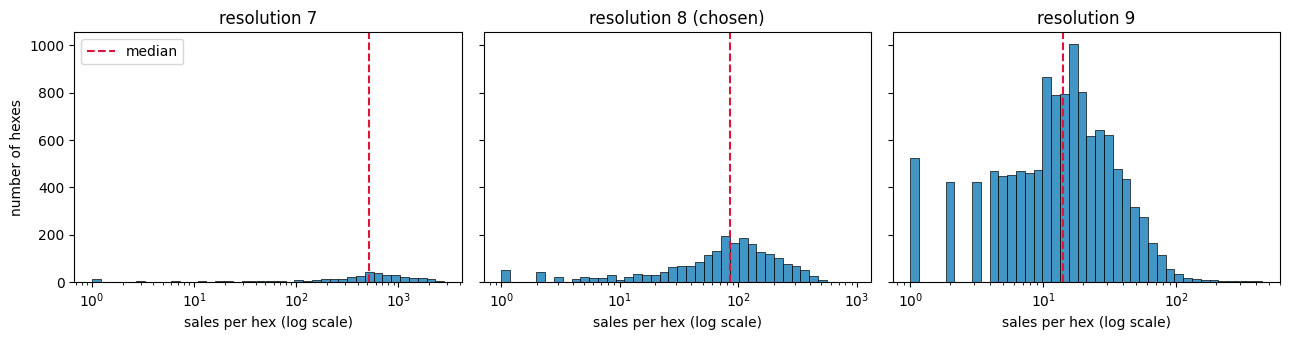

In [14]:
import h3
from src.features import HEX_RESOLUTION

res_counts = {}
for res in [7, 8, 9]:
    hexes = [h3.latlng_to_cell(lat, lon, res) for lat, lon in zip(df['lat'], df['long'])]
    res_counts[res] = pd.Series(hexes).value_counts()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (res, counts) in zip(axes, res_counts.items()):
    sns.histplot(counts, bins=40, log_scale=(True, False), ax=ax)
    ax.axvline(counts.median(), color='crimson', linestyle='--', label='median')
    ax.set_title(f'resolution {res}' + (' (chosen)' if res == HEX_RESOLUTION else ''))
    ax.set_xlabel('sales per hex (log scale)')
axes[0].set_ylabel('number of hexes')
axes[0].legend()
plt.tight_layout()

pd.DataFrame({res: counts.describe(percentiles=[.5, .9]) for res, counts in res_counts.items()}).T[
    ['count', 'min', '50%', '90%', 'max']
].rename(columns={'count': 'n_hexes', '50%': 'median', '90%': '90th percentile'})

resolution 7 is too coarse -- hundreds of sales per hex blur genuinely different micro-areas together. resolution 9 drops most hexes to single digits, too sparse for a stable local trend. resolution 8 medians in the tens-to-low-hundreds with the 90th percentile comfortably in double digits -- confirms the choice already made in `features.py`.

## distance from central london vs price

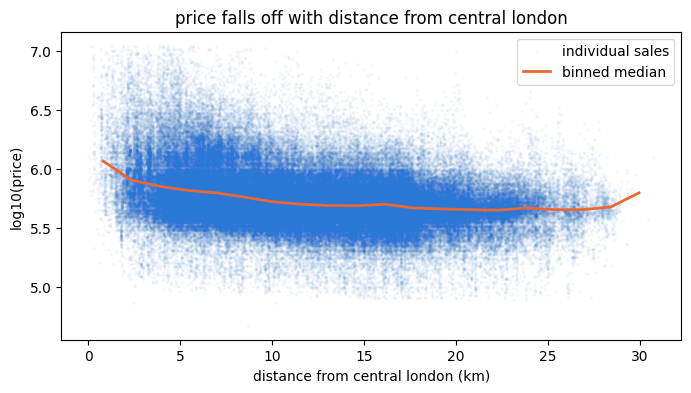

In [15]:
from src.features import add_distance_to_centre

df_dist = add_distance_to_centre(df.copy())
df_dist['log_price'] = df_dist['price'].apply('log10')
df_dist['dist_bin'] = pd.cut(df_dist['dist_to_centre_km'], bins=20)
binned = df_dist.groupby('dist_bin', observed=True)['log_price'].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df_dist['dist_to_centre_km'], df_dist['log_price'], s=2, alpha=0.03, color='#2a78d6', label='individual sales')
ax.plot([b.mid for b in binned.index], binned.values, color='#eb6834', linewidth=2, label='binned median')
ax.set_xlabel('distance from central london (km)')
ax.set_ylabel('log10(price)')
ax.set_title('price falls off with distance from central london')
ax.legend()

clear, roughly monotonic decline, steepest in the first ~15km then flattening out further away. a single distance number captures most of the gradient, but the scatter around the trend line is wide -- distance alone leaves a lot unexplained, which is what the hex-level features below are for.

## mapping price by area

median price per hex (at least 5 sales required, so a single outlier sale can't dominate a cell).

In [16]:
from src.features import add_hex_id

df_hex = add_hex_id(df_dist.copy())
hex_district = df_hex.groupby('hex_id')['district'].agg(lambda s: s.value_counts().idxmax())
hex_stats = df_hex.groupby('hex_id').agg(median_price=('price', 'median'), n_sales=('price', 'size'))
hex_stats = hex_stats[hex_stats['n_sales'] >= 5].join(hex_district.rename('district'))

def hex_geojson(hex_ids):
    features = []
    for h in hex_ids:
        boundary = h3.cell_to_boundary(h)
        ring = [[lng, lat] for lat, lng in boundary]
        ring.append(ring[0])
        features.append({'type': 'Feature', 'id': h, 'geometry': {'type': 'Polygon', 'coordinates': [ring]}})
    return {'type': 'FeatureCollection', 'features': features}

plot_df = hex_stats.reset_index()
plot_df['log_median_price'] = plot_df['median_price'].apply('log10')
geojson = hex_geojson(plot_df['hex_id'])
fig = px.choropleth_map(
    plot_df, geojson=geojson, locations='hex_id',
    color='log_median_price', hover_name='district',
    hover_data={'median_price': ':,.0f', 'n_sales': True, 'log_median_price': False, 'hex_id': False},
    color_continuous_scale='viridis', map_style='carto-positron',
    center={'lat': 51.5074, 'lon': -0.1278}, zoom=8.5, height=650, opacity=0.75,
    labels={'log_median_price': 'median price (log scale)'},
)
fig.update_layout(title='median sale price by area')
fig.show()

central and west london hexes dominate as expected, but it's not a clean ring around the centre -- some pockets well outside zone 1 sit as high as inner-west-london hexes (hover over richmond, or hampstead/highgate, both flagged below). that's the motivation for hex-level features rather than distance-only.

## areas that outperform distance alone

fit price on distance-to-centre only, then find which hexes sit furthest above that line -- areas distance systematically underprices.

In [17]:
from sklearn.linear_model import LinearRegression

X = df_hex[['dist_to_centre_km']]
y = df_hex['price'].apply('log10')
lr = LinearRegression().fit(X, y)
df_hex['dist_resid'] = y - lr.predict(X)

hex_resid = df_hex.groupby('hex_id').agg(mean_resid=('dist_resid', 'mean'), n_sales=('dist_resid', 'size'))
hex_resid = hex_resid.join(hex_district.rename('district'))
hex_resid = hex_resid[hex_resid['n_sales'] >= 10].sort_values('mean_resid', ascending=False)
hex_resid.head(10)[['district', 'mean_resid', 'n_sales']].rename(
    columns={'mean_resid': 'price premium over distance-only prediction (log scale)'}
)

,district,price premium over distance-only prediction (log scale),n_sales
hex_id,,,
88195da457fffff,BARNET,0.977613,13
88195da41dfffff,BARNET,0.844247,10
88195daf17fffff,HILLINGDON,0.764316,11
88194ad737fffff,BROMLEY,0.721749,31
88195da757fffff,BARNET,0.696761,15
88194ad8edfffff,KINGSTON UPON THAMES,0.614927,17
88195da40bfffff,BARNET,0.590681,65
88195dae21fffff,HARROW,0.582053,15
88194ad8e9fffff,KINGSTON UPON THAMES,0.578358,30


top hexes cluster around hampstead/highgate (north london) and a few leafy outer pockets -- plausible, recognisable premium areas rather than scattered noise, even after the `n_sales >= 10` floor. exactly the kind of local effect the hex features are meant to capture.

## feature correlation check

reading this: values near +1 mean two things move together, near -1 means they move in opposite directions, near 0 means little relationship.

Text(0.5, 1.0, 'how the engineered features relate to each other and to price')

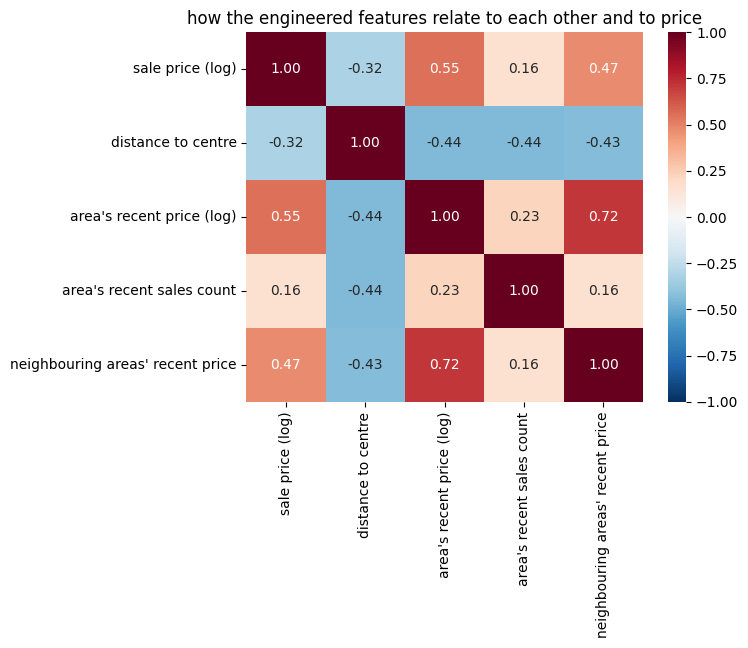

In [18]:
from src.features import add_hex_trailing_stats, add_neighbour_lag, add_date_parts

df_feat = add_date_parts(df_hex.copy())
df_feat, trailing_lookup = add_hex_trailing_stats(df_feat)
df_feat = add_neighbour_lag(df_feat, trailing_lookup)
df_feat['log_price'] = df_feat['price'].apply('log10')
df_feat['log_hex_trailing_price'] = df_feat['hex_trailing_price'].apply('log10')

corr_cols = {
    'log_price': 'sale price (log)',
    'dist_to_centre_km': 'distance to centre',
    'log_hex_trailing_price': "area's recent price (log)",
    'hex_trailing_count': "area's recent sales count",
    'hex_neighbour_lag': "neighbouring areas' recent price",
}
corr = df_feat[list(corr_cols)].rename(columns=corr_cols).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0)
plt.title("how the engineered features relate to each other and to price")

`area's recent price` correlates strongly with sale price (expected -- it's a local price average) and with `neighbouring areas' recent price` (expected -- nearby areas tend to be similar). that overlap is intentional: the neighbour figure exists to smooth out areas with too few recent sales of their own, not to add fully independent information -- seeing it track the area's own price closely is a sign the leakage-safe construction is working as intended, not a problem to fix.

## what carries forward to modelling

feature engineering explored here -- hex indexing, distance-to-centre, trailing local price/count, neighbour lag -- lives in `src/features.py` and feeds `02_modelling.ipynb`. summary: property type / new-build / tenure are collinear by the UK's lease structure but each add distinct signal; distance captures the broad gradient but misses real local hotspots; the two hex-level price features are correlated by design; `sale_month` captures a small but real seasonal effect; the march/april 2025 SDLT rush is a known, dateable anomaly in the volume data, not a leak.